# Applied statistics case studies: process control and service-time diagnosis

Two small business cases, each worked through with estimation, confidence intervals, hypothesis tests and an explicit check of the assumptions behind each test.

- **Case A: canned cat food filling.** Is the filling process under control with respect to the legal lower limit (2.95 oz) and the spill / give-away upper limit (3.10 oz)? Do the two shifts differ?
- **Case B: restaurant delivery times.** After a new cook and a new courier started, customers complained about deliveries taking longer than 25 minutes. Who, if anyone, is responsible?

**Methods:**
- descriptive statistics and diagnostic plots, including normality and randomness checks;
- t- and z-intervals; chi-square intervals for the standard deviation;
- intervals for proportions and for differences of proportions (Agresti–Coull and Agresti–Caffo);
- one-sided z-tests for means, exact binomial tests, Welch tests, process capability indices;
- a **two-way ANOVA** that separates the effect of the cook from the effect of the courier.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

plt.rcParams["figure.figsize"] = (10, 3.5)

def describe(df):
    out = df.describe().T
    out["skewness"] = df.skew()
    out["Shapiro-Wilk p"] = [stats.shapiro(df[c]).pvalue for c in df]
    return out.round(4)

def diagnostic_plots(series, title):
    """histogram, box plot, run-order plot and normal Q-Q plot for each series in a dict"""
    fig, axes = plt.subplots(len(series), 4, figsize=(14, 2.8 * len(series)))
    for row, (name, x) in zip(np.atleast_2d(axes), series.items()):
        row[0].hist(x, bins=12, color="steelblue", edgecolor="white"); row[0].set_title(f"{name}: histogram")
        row[1].boxplot(x, orientation="horizontal"); row[1].set_title("box plot")
        row[2].plot(np.arange(1, len(x) + 1), x, ".-"); row[2].set_title("in order of observation")
        sm.qqplot(np.asarray(x), line="s", ax=row[3], markersize=3); row[3].set_title("normal Q-Q")
    fig.suptitle(title); plt.tight_layout(); plt.show()

def t_interval(x, conf=0.95):
    x = np.asarray(x); h = stats.t.ppf((1 + conf) / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h

def sd_interval(x, conf=0.95):
    x = np.asarray(x); n = len(x); s2 = x.var(ddof=1); a = 1 - conf
    return np.sqrt((n - 1) * s2 / stats.chi2.ppf(1 - a / 2, n - 1)), np.sqrt((n - 1) * s2 / stats.chi2.ppf(a / 2, n - 1))

def agresti_coull(x, n, conf=0.95):
    z = stats.norm.ppf((1 + conf) / 2); p = (x + 2) / (n + 4); h = z * np.sqrt(p * (1 - p) / (n + 4))
    return max(p - h, 0), min(p + h, 1)

def agresti_caffo_diff(x1, n1, x2, n2, conf=0.95):
    z = stats.norm.ppf((1 + conf) / 2); p1, p2 = (x1 + 1) / (n1 + 2), (x2 + 1) / (n2 + 2)
    h = z * np.sqrt(p1 * (1 - p1) / (n1 + 2) + p2 * (1 - p2) / (n2 + 2))
    return p1 - p2 - h, p1 - p2 + h

# Case A: canned cat food filling

Cans are labelled 3 oz. Two limits matter:
- **Lower limit 2.95 oz.** This is legal: finding too many cans below it in an inspection leads to fines and bad publicity.
- **Upper limit 3.10 oz.** Above it, food spills when the can is opened, and the extra food is given away for free.

The data has 50 consecutive cans from each of two shifts. Shift 2 starts right after shift 1, and the cans are recorded in production order.

In [2]:
cans = pd.read_excel("data/CF1.xlsx")
LOWER, UPPER = 2.95, 3.10
describe(cans)

,count,mean,std,min,25%,50%,75%,max,skewness,Shapiro-Wilk p
Shift1,50.0,2.9998,0.0632,2.87,2.97,3.000,3.04,3.14,-0.0876,0.3363
Shift2,50.0,3.0154,0.0411,2.92,2.98,3.015,3.04,3.11,0.0369,0.7134


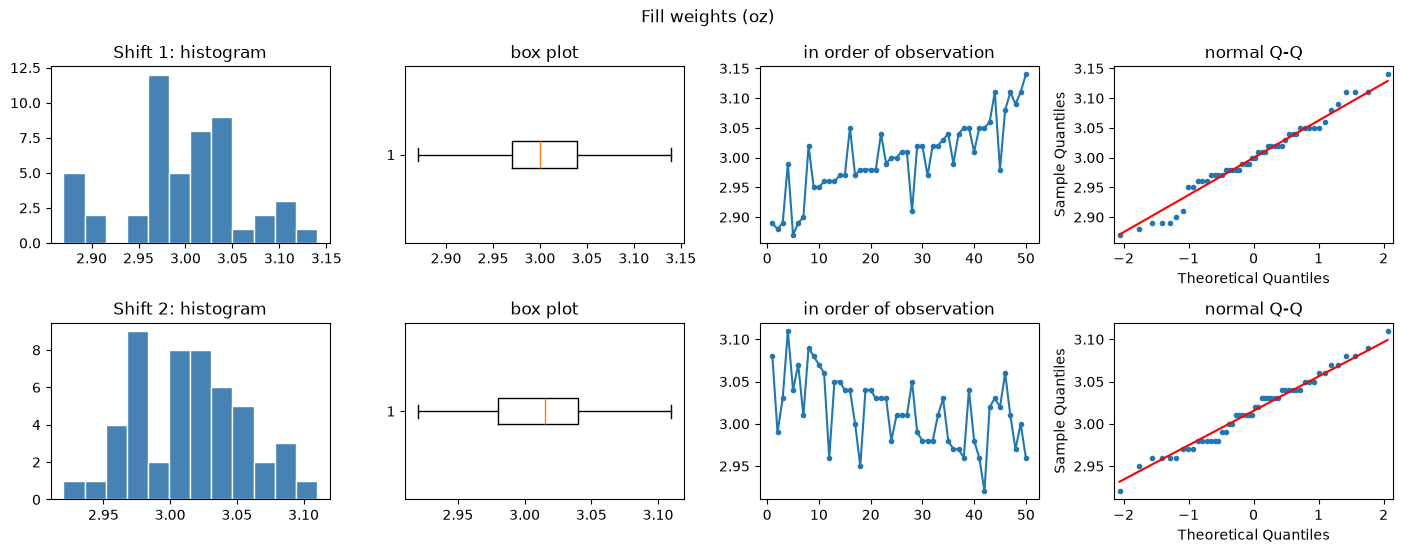

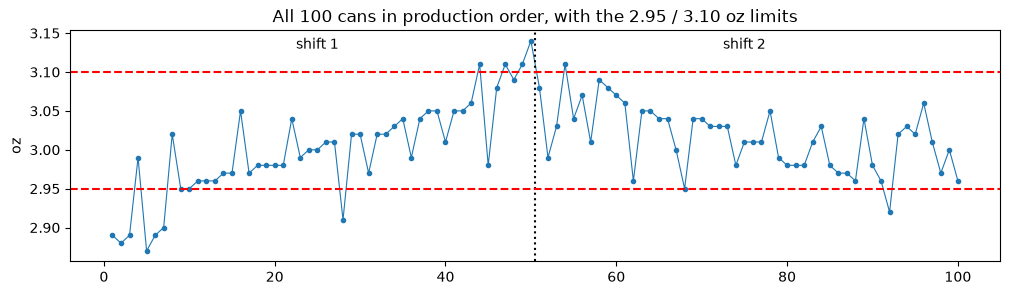

Shift1: linear trend +0.180 oz over the shift (p = 0.0000); Shift1: lag-1 autocorrelation +0.58, runs test p = 0.004
Shift2: linear trend -0.075 oz over the shift (p = 0.0001); Shift2: lag-1 autocorrelation +0.32, runs test p = 0.022


In [3]:
diagnostic_plots({"Shift 1": cans["Shift1"], "Shift 2": cans["Shift2"]}, "Fill weights (oz)")

plt.figure(figsize=(12, 3))
weights = pd.concat([cans["Shift1"], cans["Shift2"]], ignore_index=True)
plt.plot(np.arange(1, 101), weights, ".-", lw=0.8)
plt.axvline(50.5, color="k", ls=":"); plt.axhline(LOWER, color="r", ls="--"); plt.axhline(UPPER, color="r", ls="--")
plt.text(25, 3.13, "shift 1", ha="center"); plt.text(75, 3.13, "shift 2", ha="center")
plt.title("All 100 cans in production order, with the 2.95 / 3.10 oz limits"); plt.ylabel("oz"); plt.show()

for s in ("Shift1", "Shift2"):
    slope = stats.linregress(np.arange(50), cans[s])
    print(f"{s}: linear trend {slope.slope * 50:+.3f} oz over the shift (p = {slope.pvalue:.4f})", end="; ")
    r1 = sm.tsa.acf(cans[s], nlags=1)[1]
    runs = sm.stats.runstest_1samp(cans[s], cutoff="median")
    print(f"{s}: lag-1 autocorrelation {r1:+.2f}, runs test p = {runs[1]:.3f}")

**Reading the diagnostics:**
- **Location:** the two shifts have almost the same mean, about 3.00 oz against 3.02 oz.
- **Spread:** shift 1 varies much more, with a standard deviation of 0.063 oz against 0.041 oz.
- **Shape:** both distributions are nearly symmetric (skewness close to 0), and Shapiro–Wilk does not reject normality. There are no outliers.
- **Randomness:** the weights are **not** a random sample. Consecutive cans are clearly correlated (lag-1 autocorrelation 0.58 in shift 1 and 0.32 in shift 2), and the runs test rejects randomness in both shifts. The run-order plot shows why:
- **Shift 1:** the fill weight *trends steadily upward*, from about 2.89 oz at the start to about 3.14 oz at the end. Its under-weight cans are at the beginning of the shift and its over-weight cans at the end.
- **Shift 2:** the weight drifts back down.

This is the classic sign of a process that is not in statistical control. A large part of shift 1's "variability" is this trend, not random noise.

**Consequence for the analysis below:** the intervals assume independent observations. With positive autocorrelation the true uncertainty is larger, so the intervals are somewhat too narrow. They are still useful for comparing the shifts, but the drift is itself a key finding.

## A1. Mean and standard deviation per shift

The sample mean and the sample variance (with $n-1$) are the unbiased estimators.
- The intervals for the **mean** use the t-distribution. They are valid here because of normality and, in any case, because $n = 50$.
- The intervals for the **standard deviation** use the chi-square distribution, which *requires* normality. That assumption is supported by the checks above.

In [4]:
rows = []
for s in ("Shift1", "Shift2"):
    x = cans[s]
    rows.append({"shift": s, "mean": x.mean(), "95% CI mean": "[%.4f, %.4f]" % t_interval(x),
                 "std dev": x.std(ddof=1), "95% CI std dev": "[%.4f, %.4f]" % sd_interval(x)})
display(pd.DataFrame(rows).round(4))

diff = cans["Shift1"].mean() - cans["Shift2"].mean()
welch = stats.ttest_ind(cans["Shift1"], cans["Shift2"], equal_var=False)
ci = welch.confidence_interval(0.95)
levene = stats.levene(cans["Shift1"], cans["Shift2"])
print(f"difference in means (shift 1 - shift 2): {diff:+.4f} oz, 95% CI [{ci.low:.4f}, {ci.high:.4f}], Welch p = {welch.pvalue:.3f}")
print(f"F-test / Levene for equal variances: variance ratio {cans.Shift1.var() / cans.Shift2.var():.2f}, Levene p = {levene.pvalue:.4f}")

,shift,mean,95% CI mean,std dev,95% CI std dev
0,Shift1,2.9998,"[2.9818, 3.0178]",0.0632,"[0.0528, 0.0788]"
1,Shift2,3.0154,"[3.0037, 3.0271]",0.0411,"[0.0343, 0.0512]"


difference in means (shift 1 - shift 2): -0.0156 oz, 95% CI [-0.0368, 0.0056], Welch p = 0.147
F-test / Levene for equal variances: variance ratio 2.37, Levene p = 0.0161


## A2. Under- and over-weight cans

There are two ways to estimate the share of cans outside the limits:
- **Empirical:** count the cans outside each limit. Agresti–Coull intervals (add 2 successes and 2 failures) behave well for small proportions, where the textbook Wald interval can even dip below zero.
- **Model-based:** if the weights are normal, $P(X < 2.95) = \Phi\big((2.95 - \hat\mu)/\hat\sigma\big)$. This uses all 50 observations instead of only the few extreme ones.

In [5]:
rows, counts = [], {}
for s in ("Shift1", "Shift2"):
    x = cans[s]; n = len(x); mu, sd = x.mean(), x.std(ddof=1)
    under, over = int((x < LOWER).sum()), int((x > UPPER).sum())
    counts[s] = (under, over, n)
    rows.append({"shift": s,
                 "under 2.95: count": under, "share": under / n, "95% CI": "[%.3f, %.3f]" % agresti_coull(under, n),
                 "normal model": stats.norm.cdf(LOWER, mu, sd),
                 "over 3.10: count": over, "share ": over / n, "95% CI ": "[%.3f, %.3f]" % agresti_coull(over, n),
                 "normal model ": stats.norm.sf(UPPER, mu, sd)})
pd.DataFrame(rows).round(4)

,shift,under 2.95: count,share,95% CI,normal model,over 3.10: count,share,95% CI,normal model
0,Shift1,7,0.14,"[0.067, 0.266]",0.2155,4,0.08,"[0.027, 0.195]",0.0565
1,Shift2,1,0.02,"[0.000, 0.117]",0.0556,1,0.02,"[0.000, 0.117]",0.0197


In [6]:
(u1, o1, n1), (u2, o2, n2) = counts["Shift1"], counts["Shift2"]
for label, a, b in (("under-weight", u1, u2), ("over-weight", o1, o2)):
    lo, hi = agresti_caffo_diff(a, n1, b, n2)
    fisher = stats.fisher_exact([[a, n1 - a], [b, n2 - b]])
    print(f"{label}: shift 1 - shift 2 = {a / n1 - b / n2:+.3f}, 95% CI [{lo:.3f}, {hi:.3f}], Fisher exact p = {fisher.pvalue:.3f}")

under-weight: shift 1 - shift 2 = +0.120, 95% CI [0.004, 0.227], Fisher exact p = 0.059
over-weight: shift 1 - shift 2 = +0.060, 95% CI [-0.038, 0.153], Fisher exact p = 0.362


## A3. Process capability

Capability indices relate the process spread to the width of the specification:
- $C_p = (\text{USL} - \text{LSL}) / 6\sigma$ measures the spread alone;
- $C_{pk} = \min(\text{USL} - \mu,\ \mu - \text{LSL}) / 3\sigma$ also penalises a mean that is off-centre.

A common rule of thumb asks for $C_{pk} \ge 1.33$.

In [7]:
target = (LOWER + UPPER) / 2
for s in ("Shift1", "Shift2"):
    mu, sd = cans[s].mean(), cans[s].std(ddof=1)
    cp = (UPPER - LOWER) / (6 * sd); cpk = min(UPPER - mu, mu - LOWER) / (3 * sd)
    print(f"{s}: mean {mu:.4f} (spec centre {target:.3f}), Cp = {cp:.2f}, Cpk = {cpk:.2f}")

Shift1: mean 2.9998 (spec centre 3.025), Cp = 0.40, Cpk = 0.26
Shift2: mean 3.0154 (spec centre 3.025), Cp = 0.61, Cpk = 0.53


## A4. Conclusions for the production manager

- **The shifts fill to the same average.** The 95% CI for the difference in means contains 0.
- **The shifts differ clearly in consistency.** Shift 1's variance is about 2.4 times shift 2's (Levene p ≈ 0.016). As a result, shift 1 produces many more out-of-limit cans: 14% under-weight and 8% over-weight, against 2% and 2% in shift 2.
- **The process is not in control.**
  - In shift 1 the fill weight climbs throughout the shift, which explains both its under-weight cans (at the start) and its over-weight cans (at the end).
  - In shift 2 it drifts back down.

  Much of the variation is therefore *systematic*, and it can be removed by re-adjusting the filler.
- **Neither shift is capable.**
  - Shift 1 has $C_p = 0.40$ and $C_{pk} = 0.26$; shift 2 has $C_p = 0.61$ and $C_{pk} = 0.53$. Both are far below the usual target of 1.33.
  - The 0.15 oz specification window is narrow relative to the process spread.
  - Shift 1's mean (3.000 oz) also sits lower than shift 2's (3.015 oz), nearer the legal limit, while the centre of the window is 3.025 oz.
- **Recommendations:**
  - Use control charts on the run order (for example, an individuals chart with a moving range) to detect the drift as it happens.
  - Investigate what changes over a shift: filler calibration, product temperature or consistency, and operator adjustments.
  - Re-calibrate the filler at the start of each shift and at regular intervals.
  - Focus first on shift 1, whose larger spread causes most of the out-of-limit cans.
  - Raising the target slightly would also move the mean away from the legal limit.
- **Caveat on the proportions.** With only 1–7 cans outside the limits per shift, the evidence is limited:
  - the under-weight difference is borderline (Agresti–Caffo CI just excludes 0, Fisher exact p ≈ 0.06);
  - the over-weight difference is not significant.

  The variance comparison is the stronger evidence.

# Case B: restaurant delivery times

**The restaurant** promises delivery within 25 minutes.
- The owner, who is also the cook, Kamil Usta, hired a new cook, **Suphi Usta**, for the shift from 19:00.
- One of the two couriers was replaced by a new courier, **Mehmet**. The other courier is **Ahmet**.
- Complaints about late deliveries followed.

**The data:** preparation time, travel time and total time for 27 peak-hour deliveries (18:00–20:00) by each courier, in delivery order. About half of each courier's deliveries happened before 19:00, when Kamil cooked, and half after, when Suphi cooked.

**Known standard deviations** (given): 1 minute for preparation times, 3.5 minutes for travel times, 3.64 minutes for total times.

In [8]:
ahmet = pd.read_excel("data/Ahmet.xlsx").rename(columns=str.lower).rename(columns=lambda c: c.replace("_", "").replace("time", "_time"))
mehmet = pd.read_excel("data/Mehmet.xlsx").rename(columns=str.lower).rename(columns=lambda c: c.replace("_", "").replace("time", "_time"))
kamil = pd.read_excel("data/KamilUsta.xlsx")["PrepTime"]
suphi = pd.read_excel("data/SuphiUsta.xlsx")["PrepTime"]
SIGMA_PREP, SIGMA_TRAVEL, SIGMA_TOTAL, PROMISE = 1.0, 3.5, 3.64, 25

# which cook prepared each delivery: the cook's prep times appear in the same order in the courier files
assert not set(kamil.round(1)) & set(suphi.round(1))      # the two cooks' times never coincide
def cook_of(prep):
    return np.where(prep.round(1).isin(suphi.round(1)), "Suphi", "Kamil")
ahmet["cook"], mehmet["cook"] = cook_of(ahmet["prep_time"]), cook_of(mehmet["prep_time"])
deliveries = pd.concat([ahmet.assign(courier="Ahmet"), mehmet.assign(courier="Mehmet")], ignore_index=True)
print(pd.crosstab(deliveries["courier"], deliveries["cook"]))
deliveries.groupby("courier")[["prep_time", "travel_time", "total_time"]].mean().round(2)

cook     Kamil  Suphi
courier              
Ahmet       13     14
Mehmet      14     13


,prep_time,travel_time,total_time
courier,,,
Ahmet,12.39,7.67,19.73
Mehmet,11.84,8.67,20.52


## B1. Couriers: travel time

,count,mean,std,min,25%,50%,75%,max,skewness,Shapiro-Wilk p
Ahmet,27.0,7.6667,3.4775,1.9,5.65,7.4,9.90,15.6,0.2998,0.5523
Mehmet,27.0,8.6741,3.9389,1.1,6.70,7.7,10.65,17.0,0.4267,0.2970


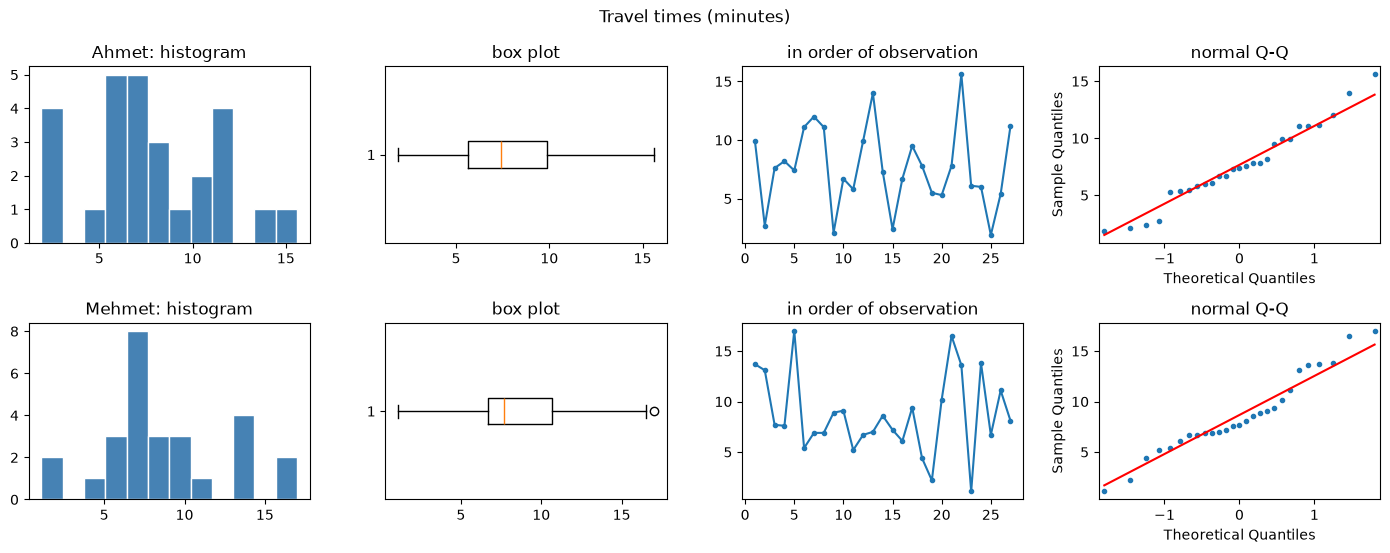

In [9]:
display(describe(pd.DataFrame({"Ahmet": ahmet["travel_time"], "Mehmet": mehmet["travel_time"]})))
diagnostic_plots({"Ahmet": ahmet["travel_time"], "Mehmet": mehmet["travel_time"]}, "Travel times (minutes)")

**Does either courier exceed the 8-minute travel target?** The test is one-sided: $H_0: \mu \le 8$ against $H_a: \mu > 8$.
- The population standard deviation is known (3.5 minutes), so a **z-test** is appropriate.
- It needs either normal data or a large enough sample (n = 27, and the travel times look roughly normal).
- It also needs independent deliveries. The run-order plots show no trend.

In [10]:
def z_test_upper(x, mu0, sigma):
    z = (np.mean(x) - mu0) / (sigma / np.sqrt(len(x)))
    return z, stats.norm.sf(z)

for name, x in (("Ahmet", ahmet["travel_time"]), ("Mehmet", mehmet["travel_time"])):
    z, p = z_test_upper(x, 8, SIGMA_TRAVEL)
    print(f"{name}: mean travel {x.mean():.2f} min, z = {z:+.2f}, one-sided p = {p:.3f}")

w = stats.ttest_ind(ahmet["travel_time"], mehmet["travel_time"], equal_var=False)
print(f"Ahmet vs Mehmet travel time: Welch p = {w.pvalue:.3f}")

Ahmet: mean travel 7.67 min, z = -0.49, one-sided p = 0.690
Mehmet: mean travel 8.67 min, z = +1.00, one-sided p = 0.158
Ahmet vs Mehmet travel time: Welch p = 0.324


## B2. Share of deliveries within 25 minutes

The owner wants at least 90% of deliveries within 25 minutes, so the test is $H_0: p \ge 0.9$ against $H_a: p < 0.9$.

The usual large-sample z-test for a proportion needs $n p_0 (1 - p_0) \ge 5$. Here that is $27 \times 0.9 \times 0.1 = 2.4$, so the normal approximation is **not** reliable. The **exact binomial test** is used instead, with the z-test shown for comparison.

In [11]:
for name, df in (("Ahmet", ahmet), ("Mehmet", mehmet)):
    n = len(df); on_time = int((df["total_time"] <= PROMISE).sum()); p_hat = on_time / n
    exact = stats.binomtest(on_time, n, 0.9, alternative="less")
    z = (p_hat - 0.9) / np.sqrt(0.9 * 0.1 / n)
    print(f"{name}: {on_time}/{n} on time = {p_hat:.3f} | exact binomial p = {exact.pvalue:.3f} | "
          f"(z-approximation p = {stats.norm.cdf(z):.3f})")

Ahmet: 24/27 on time = 0.889 | exact binomial p = 0.515 | (z-approximation p = 0.424)
Mehmet: 21/27 on time = 0.778 | exact binomial p = 0.047 | (z-approximation p = 0.017)


## B3. Cooks: preparation time

,count,mean,std,min,25%,50%,75%,max,skewness,Shapiro-Wilk p
Kamil,27.0,8.1296,1.0866,5.9,7.45,8.3,8.8,10.4,-0.1598,0.7830
Suphi,27.0,16.1074,0.9059,14.1,15.50,16.1,16.8,17.7,-0.3680,0.5496


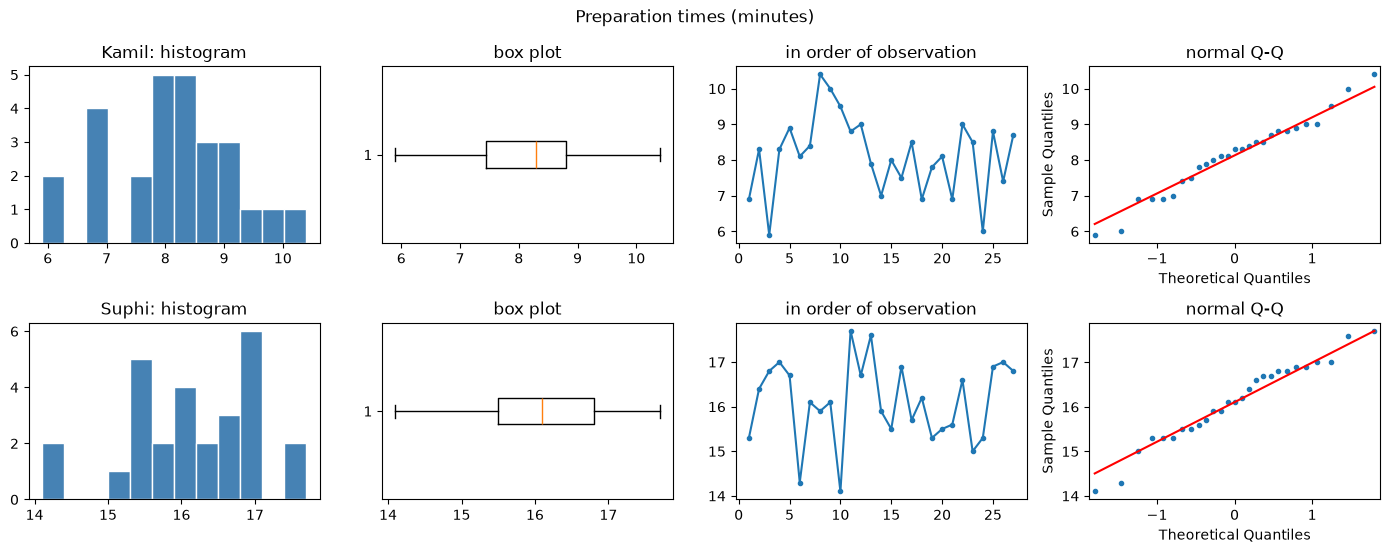

Kamil: mean prep 8.13 min, H0: mu <= 10 -> z = -9.72, one-sided p = 1.0000
Suphi: mean prep 16.11 min, H0: mu <= 10 -> z = +31.74, one-sided p = 0.0000


In [12]:
display(describe(pd.DataFrame({"Kamil": kamil, "Suphi": suphi})))
diagnostic_plots({"Kamil": kamil, "Suphi": suphi}, "Preparation times (minutes)")

for name, x in (("Kamil", kamil), ("Suphi", suphi)):
    z, p = z_test_upper(x, 10, SIGMA_PREP)
    print(f"{name}: mean prep {x.mean():.2f} min, H0: mu <= 10 -> z = {z:+.2f}, one-sided p = {p:.4f}")

## B4. Who causes the late deliveries? A two-way ANOVA

Total delivery time is preparation time plus travel time, and every delivery has *both* a cook and a courier. Comparing the couriers' totals alone mixes the two effects, because each courier delivered food from both cooks.

A two-way ANOVA of total time on **cook** and **courier**, with their interaction, separates the effects.

In [13]:
late = deliveries[deliveries["total_time"] > PROMISE]
print(f"late deliveries (> {PROMISE} min): {len(late)} of {len(deliveries)}")
print(late.groupby(["cook", "courier"]).size().rename("late deliveries").to_string(), "\n")

anova_model = smf.ols("total_time ~ C(cook) * C(courier)", data=deliveries).fit()
display(sm.stats.anova_lm(anova_model, typ=2).round(4))
display(deliveries.pivot_table(index="cook", columns="courier", values="total_time", aggfunc="mean").round(2))

late deliveries (> 25 min): 9 of 54
cook   courier
Suphi  Ahmet      3
       Mehmet     6 



,sum_sq,df,F,PR(>F)
C(cook),626.4096,1.0,40.9894,0.0000
C(courier),14.7237,1.0,0.9634,0.3310
C(cook):C(courier),20.9908,1.0,1.3735,0.2468
Residual,764.1122,50.0,NaN,NaN


courier,Ahmet,Mehmet
cook,,
Kamil,16.84,16.64
Suphi,22.41,24.70


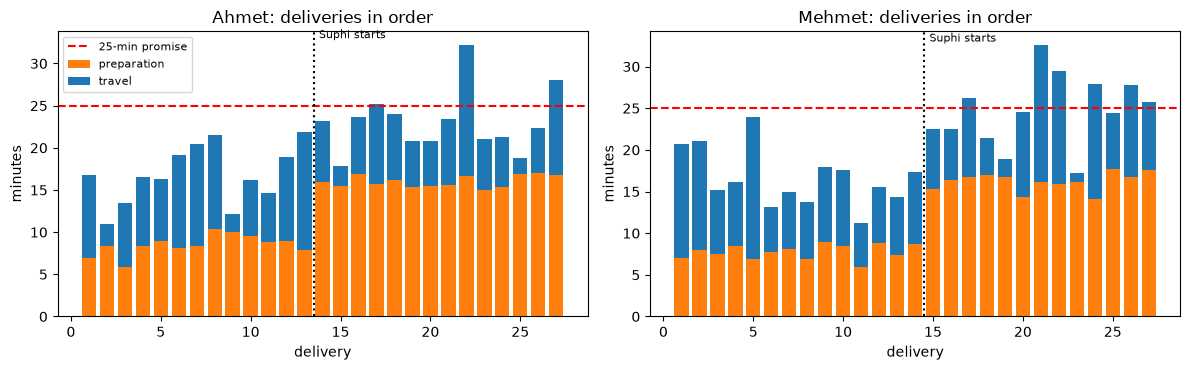

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, df) in zip(axes, (("Ahmet", ahmet), ("Mehmet", mehmet))):
    ax.bar(np.arange(1, len(df) + 1), df["prep_time"], label="preparation", color="tab:orange")
    ax.bar(np.arange(1, len(df) + 1), df["travel_time"], bottom=df["prep_time"], label="travel", color="tab:blue")
    ax.axhline(PROMISE, color="r", ls="--", label="25-min promise")
    switch = np.argmax(df["cook"].values == "Suphi") + 0.5
    ax.axvline(switch, color="k", ls=":"); ax.text(switch + 0.3, 33, "Suphi starts", fontsize=8)
    ax.set_title(f"{name}: deliveries in order"); ax.set_xlabel("delivery"); ax.set_ylabel("minutes")
axes[0].legend(loc="upper left", fontsize=8); plt.tight_layout(); plt.show()

## B5. Conclusions for the owner

- **The cook drives the delays, not the courier.**
  - Suphi's preparation time averages 16.1 minutes, against 8.1 for Kamil, far above the 10-minute target (z ≈ 32).
  - **All nine late deliveries** happened after 19:00, when Suphi was cooking.
  - In the two-way ANOVA, the cook effect is large and highly significant (F ≈ 41, p < 0.001). The courier effect (p ≈ 0.33) and the cook × courier interaction (p ≈ 0.25) are not.
  - On Kamil's orders both couriers average about 16.7 minutes in total. On Suphi's orders it is 22.4 minutes for Ahmet and 24.7 for Mehmet.
- **Mehmet's record looks worse, but mostly because of the kitchen.**
  - Mehmet's on-time share (78%) is significantly below the 90% target (exact binomial p ≈ 0.047); Ahmet's (89%) is not.
  - But Mehmet's mean travel time (8.7 min) does not significantly exceed the 8-minute target (p ≈ 0.16), and Mehmet is not significantly slower than Ahmet (p ≈ 0.32).
  - All six of Mehmet's late deliveries were Suphi-cooked orders. Mehmet's slightly longer and more variable travel times push more of those already-slow orders over 25 minutes.
- **Correct inference for small proportions.** With 27 deliveries the normal approximation for the 90% test is unreliable. It gives p ≈ 0.017 for Mehmet and overstates the evidence, compared with the exact p ≈ 0.047.
- **Recommendation:** focus on Suphi's preparation process, for example through training, pre-preparing ingredients for the evening peak, or a second cook during peak hours. Monitor Mehmet's travel times, but do not blame the courier for the complaints.
- **Caveats:**
  - Cook and time of day are confounded: Suphi only works after 19:00, when traffic and order volume may also differ. Data on Kamil cooking after 19:00, or Suphi before, would separate them.
  - Each courier's 27 deliveries are a small sample, so the travel-time comparison has limited power.